In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.tree import DecisionTreeClassifier

In [3]:
# Dataset sintetis untuk simulasi
# Dataset dapat diganti dengan dataset nyata dari UCI atau Kaggle

X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=6,
    weights=[0.8, 0.2],
    random_state=42
)

print("Distribusi kelas:", np.bincount(y))

Distribusi kelas: [797 203]


In [4]:
# Membagi dataset menjadi data training dan testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Proporsi kelas train:",
      np.bincount(y_train) / len(y_train))

print("Proporsi kelas test:",
      np.bincount(y_test) / len(y_test))

Proporsi kelas train: [0.7975 0.2025]
Proporsi kelas test: [0.795 0.205]


In [5]:
# Membuat model Decision Tree

model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

# Menghitung learning curve

train_sizes, train_scores, val_scores = learning_curve(
    model,
    X_train,
    y_train,
    cv=5,
    train_sizes=np.linspace(0.1, 1.0, 8),
    scoring="accuracy"
)

# Menghitung rata-rata skor training dan validasi

train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

In [6]:
print("Skor train pada ukuran data terbesar:",
      round(train_mean[-1], 3))

print("Skor validasi pada ukuran data terbesar:",
      round(val_mean[-1], 3))

print("Gap (indikasi overfitting jika besar):",
      round(train_mean[-1] - val_mean[-1], 3))

Skor train pada ukuran data terbesar: 0.929
Skor validasi pada ukuran data terbesar: 0.885
Gap (indikasi overfitting jika besar): 0.044


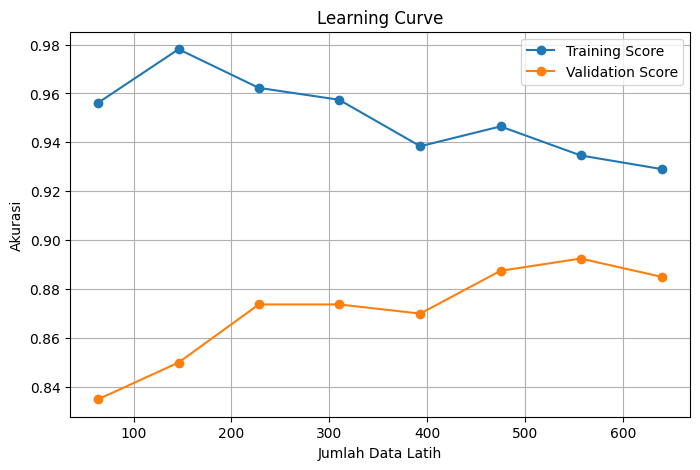

In [7]:
# Membuat grafik Learning Curve

plt.figure(figsize=(8, 5))

plt.plot(
    train_sizes,
    train_mean,
    'o-',
    label='Training Score'
)

plt.plot(
    train_sizes,
    val_mean,
    'o-',
    label='Validation Score'
)

plt.xlabel('Jumlah Data Latih')
plt.ylabel('Akurasi')
plt.title('Learning Curve')

plt.legend()
plt.grid(True)

plt.show()